# Document-level CID relation extraction (Zheng et al., 2018)

Goal: for every (chemical, disease) pair in a PubMed abstract, predict whether the chemical
causes the disease (CID = chemical-induced disease).

Paper: *An effective neural model extracting document level chemical-induced disease relations
from biomedical literature* (JBI 83, 2018). DOI: https://doi.org/10.1016/j.jbi.2018.05.001

This notebook follows the paper pipeline (preprocessing, BiLSTM+CNN model, post-processing rules)
using **local CDR data** under `Dataset/` and **Stanford CoreNLP** for sentence split / tokenize / POS
(paper §2.2.2). If Java + CoreNLP are not installed, it falls back to **Stanza** (Stanford NLP Group)
so the notebook still runs.

## Part 1. Setup

### CoreNLP (paper-faithful)

This machine is set up with:

1. **JDK 11** at `C:\Program Files\Java\jdk-11.0.33.0.3` (auto-detected if not on `PATH`).
2. **Stanford CoreNLP 4.6.0** in `stanford-corenlp-4.6.0/` (auto-detected as `CORENLP_HOME`).
3. **English-extra models** in `corenlp-english-extra/` (copied into the CoreNLP folder on first run).

You can still override with env vars `JAVA_HOME` / `CORENLP_HOME`.

GPU (optional): Colab *Runtime → GPU*, or a local CUDA TensorFlow build.

In [38]:
# Run once per environment. Uses the Python of THIS kernel (your old `%pip` cell failed:
# "No module named pip"). Installs only what is missing.
import importlib.util, subprocess, sys

packages = {"tensorflow": "tensorflow", "gensim": "gensim", "sklearn": "scikit-learn",
            "stanfordcorenlp": "stanfordcorenlp", "stanza": "stanza", "matplotlib": "matplotlib"}
missing = [pip_name for module, pip_name in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "ensurepip", "--upgrade"], check=False)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)
print("installed now:", missing or "nothing (all present)")

installed now: nothing (all present)


In [39]:
import os, re, random, zipfile, urllib.request, json, subprocess, shutil, gc, pickle
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
from gensim.models import Word2Vec

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

# ---- GPU: growth so TF does not grab the whole 6 GB at once ----
gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except Exception as e:
        print("memory_growth:", e)

# ---- Settings from the paper (section 3.3) ----
K_WINDOW      = 4
MAX_SENTS     = 30
MAX_WORDS     = 120
WORD_DIM      = 100
POS_DIM       = 10
CNN_WINDOW    = 5
CNN_FILTERS   = 300
DROPOUT       = 0.5
LEARNING_RATE = 0.001
BATCH_SIZE    = 4          # paper: 8. 4 fits a 6 GB laptop GPU
THRESHOLD     = 0.5        # paper Eq. 10 (Fig. 3: 0.5 was best on dev)
MAX_EPOCHS    = 40         # paper does not say; early stopping on dev F1 decides
PATIENCE      = 5          # stop after 5 epochs without a better dev F1
USE_CLASS_WEIGHT = False   # paper: plain cross-entropy. True = up-weight CID positives
THRESH_GRID   = [round(float(t), 2) for t in np.arange(0.10, 0.91, 0.05)]  # extra dev sweep

# ---- Paper experiments in Part 9. Each one retrains the model (about as long as the main run).
RUN_TABLE3_INPUTS = False    # 2 extra trainings
RUN_TABLE6_ARCH = False    # 3 extra trainings
RUN_TABLE9_DATA = False    # 1 extra training
RUN_SEEDS         = False   # 3 extra trainings of the full model (mean +/- std)
ABLATION_MAX_EPOCHS = MAX_EPOCHS   # lower these to save time (e.g. 15 / 3)
ABLATION_PATIENCE   = PATIENCE

REPO_ROOT = Path(".").resolve()
CDR_DIR = REPO_ROOT / "Dataset" / "CDR_Data" / "CDR_Data" / "CDR.Corpus.v010516"
EXTRA_MODELS = REPO_ROOT / "corenlp-english-extra" / "stanford-corenlp-models-english-extra.jar"
CORENLP_DIR = REPO_ROOT / "stanford-corenlp-4.6.0"
RESULTS_DIR = REPO_ROOT / "results"          # saved weights + scores
RESULTS_DIR.mkdir(exist_ok=True)

# ---- Saved steps: after a crash or a kernel restart, "Run All" resumes from here.
# Delete a file to redo that step (e.g. after changing preprocessing or settings).
DOCS_CACHE   = RESULTS_DIR / "prepared_docs.pkl"        # CoreNLP output
EMB_CACHE    = RESULTS_DIR / "embedding_matrices.npz"   # word + POS matrices
MESH_CACHE   = RESULTS_DIR / "mesh_tree_numbers.json"   # MeSH tree numbers
MAIN_WEIGHTS = RESULTS_DIR / "main.weights.h5"          # trained main model
RESULTS_FILE = RESULTS_DIR / "results.json"             # every score


def ram():
    """RAM used by this kernel, in GB (Linux)."""
    try:
        pages = int(open(f"/proc/{os.getpid()}/statm").read().split()[1])
        return round(pages * os.sysconf("SC_PAGE_SIZE") / 2**30, 2)
    except Exception:
        return float("nan")

def ensure_java_on_path():
    """Put JDK 11 on PATH for this process if `java` is missing."""
    if shutil.which("java"):
        return shutil.which("java")
    candidates = []
    if os.environ.get("JAVA_HOME"):
        candidates.append(Path(os.environ["JAVA_HOME"]) / "bin" / "java.exe")
    candidates += [
        Path(r"C:\Program Files\Java\jdk-11.0.33.0.3\bin\java.exe"),
        Path(r"C:\Program Files\Java\latest\bin\java.exe"),
    ]
    java_root = Path(r"C:\Program Files\Java")
    if java_root.is_dir():
        candidates += sorted(java_root.glob("jdk-11*\\bin\\java.exe"), reverse=True)
    for java_exe in candidates:
        if java_exe.is_file():
            bin_dir = str(java_exe.parent)
            os.environ["JAVA_HOME"] = str(java_exe.parent.parent)
            os.environ["PATH"] = bin_dir + os.pathsep + os.environ.get("PATH", "")
            return str(java_exe)
    return None

JAVA_EXE = ensure_java_on_path()
print("TF", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))
print("CDR_DIR exists:", CDR_DIR.is_dir())
print("CoreNLP dir:", CORENLP_DIR.is_dir(), CORENLP_DIR)
print("english-extra jar:", EXTRA_MODELS.is_file())
print("java:", JAVA_EXE or "NOT FOUND")
if JAVA_EXE:
    print(subprocess.check_output([JAVA_EXE, "-version"], stderr=subprocess.STDOUT, text=True).splitlines()[0])

TF 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
CDR_DIR exists: True
CoreNLP dir: True /home/oxored/Documents/DocCIDR/stanford-corenlp-4.6.0
english-extra jar: True
java: /usr/bin/java
openjdk version "11.0.33.1" 2026-11-17


## Part 2. Data — BioCreative V CDR (local)

1,500 PubMed abstracts (500 / 500 / 500). PubTator format:

- `PMID|t|title` and `PMID|a|abstract`
- entity: `PMID\tstart\tend\tmention\ttype\tMeSH`
- relation: `PMID\tCID\tchem-MeSH\tdisease-MeSH`

Paths: `Dataset/CDR_Data/CDR_Data/CDR.Corpus.v010516/`.

In [40]:
TRAIN_FILE = CDR_DIR / "CDR_TrainingSet.PubTator.txt"
DEV_FILE   = CDR_DIR / "CDR_DevelopmentSet.PubTator.txt"
TEST_FILE  = CDR_DIR / "CDR_TestSet.PubTator.txt"

for p in (TRAIN_FILE, DEV_FILE, TEST_FILE):
    assert p.is_file(), f"Missing {p}. Place the CDR corpus under Dataset/."
    print(p)

/home/oxored/Documents/DocCIDR/Dataset/CDR_Data/CDR_Data/CDR.Corpus.v010516/CDR_TrainingSet.PubTator.txt
/home/oxored/Documents/DocCIDR/Dataset/CDR_Data/CDR_Data/CDR.Corpus.v010516/CDR_DevelopmentSet.PubTator.txt
/home/oxored/Documents/DocCIDR/Dataset/CDR_Data/CDR_Data/CDR.Corpus.v010516/CDR_TestSet.PubTator.txt


In [41]:
def read_pubtator(path):
    """Return a list of documents. Each document is a dict."""
    docs, doc = [], None
    path = Path(path)
    for line in path.read_text(encoding="utf-8").splitlines():
        line = line.rstrip("\n")
        if line == "":
            if doc:
                docs.append(doc)
            doc = None
        elif re.match(r"^\d+\|t\|", line):
            pmid, _, title = line.split("|", 2)
            doc = {"pmid": pmid, "title": title, "abstract": "",
                   "entities": [], "cids": set()}
        elif re.match(r"^\d+\|a\|", line):
            doc["abstract"] = line.split("|", 2)[2]
        else:
            parts = line.split("\t")
            if len(parts) < 2:
                continue
            if parts[1] == "CID":
                doc["cids"].add((parts[2], parts[3]))
            else:
                mesh = parts[5] if len(parts) > 5 else ""
                ids = [i for i in mesh.split("|") if i and i != "-1"]
                if ids:
                    doc["entities"].append({
                        "start": int(parts[1]),
                        "end": int(parts[2]),
                        "text": parts[3],
                        "type": parts[4],
                        "ids": ids,
                    })
    if doc:
        docs.append(doc)
    return docs

train_docs = read_pubtator(TRAIN_FILE)
dev_docs   = read_pubtator(DEV_FILE)
test_docs  = read_pubtator(TEST_FILE)

print(len(train_docs), len(dev_docs), len(test_docs))
print(sum(len(d["cids"]) for d in train_docs + dev_docs + test_docs), "CIDs")

500 500 500
3116 CIDs


## Part 3. Preprocessing (paper §2.2.2 and §2.2.4)

1. Split title + abstract into sentences (title = sentence 0).
2. Map each entity mention to a MeSH token.
3. Replace numbers by `<num>`; POS-tag every token (CoreNLP / Stanza).
4. For each candidate pair: wrap chemical in `ch_start … ch_end`, disease in `ds_start … ds_end`;
   drop brackets that hold neither candidate.
5. On the new development set and the test set only, drop pairs whose minimum sentence span exceeds **K = 4** (§3.1). Training keeps every pair.


In [42]:
# ---------- NLP backend: CoreNLP (preferred) or Stanza ----------

class _StanzaBackend:
    """Stanford Stanza fallback when Java/CoreNLP is unavailable."""
    def __init__(self):
        import stanza
        stanza.download("en", processors="tokenize,pos", verbose=False)
        self.nlp = stanza.Pipeline(
            "en", processors="tokenize,pos", tokenize_no_ssplit=False, verbose=False
        )

    def annotate(self, text):
        doc = self.nlp(text)
        sentences = []
        for sent in doc.sentences:
            tokens = []
            for w in sent.words:
                start = int(w.start_char) if w.start_char is not None else -1
                end = int(w.end_char) if w.end_char is not None else -1
                tokens.append({"word": w.text, "pos": w.xpos or w.upos or "NN",
                               "start": start, "end": end})
            sentences.append(tokens)
        return sentences


class _CoreNLPBackend:
    """Stanford CoreNLP via stanfordcorenlp (Java server)."""
    def __init__(self, home: Path):
        from stanfordcorenlp import StanfordCoreNLP
        jars = list(Path(home).glob("stanford-corenlp-*.jar"))
        if not jars:
            raise FileNotFoundError(f"No stanford-corenlp-*.jar under {home}")
        # Prefer putting english-extra on the classpath by copying/linking into home if present
        if EXTRA_MODELS.is_file():
            dest = Path(home) / EXTRA_MODELS.name
            if not dest.exists():
                try:
                    shutil.copy2(EXTRA_MODELS, dest)
                except Exception:
                    pass
        self.nlp = StanfordCoreNLP(str(home), memory="4g", timeout=60000)
        self.props = {"annotators": "tokenize,ssplit,pos", "outputFormat": "json",
                      "tokenize.options": "ptb3Escaping=false"}

    def annotate(self, text):
        raw = self.nlp.annotate(text, properties=self.props)
        data = json.loads(raw)
        sentences = []
        for sent in data.get("sentences", []):
            tokens = []
            for t in sent.get("tokens", []):
                tokens.append({
                    "word": t.get("originalText") or t.get("word"),
                    "pos": t.get("pos", "NN"),
                    "start": int(t["characterOffsetBegin"]),
                    "end": int(t["characterOffsetEnd"]),
                })
            sentences.append(tokens)
        return sentences

    def close(self):
        try:
            self.nlp.close()
        except Exception:
            pass


def _java_ok():
    # ensure_java_on_path() already ran in the settings cell
    return shutil.which("java") is not None or JAVA_EXE is not None


def _find_corenlp_home():
    env = os.environ.get("CORENLP_HOME")
    if env and Path(env).is_dir():
        return Path(env)
    for cand in [
        CORENLP_DIR,  # DocCIDR/stanford-corenlp-4.6.0
        REPO_ROOT / "stanford-corenlp-4.6.0",
        REPO_ROOT / "stanford-corenlp",
        REPO_ROOT / "corenlp",
        Path.home() / "stanford-corenlp",
    ]:
        if cand.is_dir() and list(cand.glob("stanford-corenlp-*.jar")):
            return cand
    return None


def build_nlp_backend():
    ensure_java_on_path()
    home = _find_corenlp_home()
    if _java_ok() and home is not None:
        os.environ["CORENLP_HOME"] = str(home)
        print("Using Stanford CoreNLP at", home)
        return _CoreNLPBackend(home), "corenlp"
    print("Java/CoreNLP not ready — using Stanza (Stanford NLP) fallback.")
    print("Expected CoreNLP folder:", CORENLP_DIR)
    print("java on PATH:", shutil.which("java"), "| JAVA_EXE:", JAVA_EXE)
    return _StanzaBackend(), "stanza"


if DOCS_CACHE.is_file():
    # Documents were already annotated: no need to start the 4 GB Java server.
    NLP, NLP_BACKEND = None, "cache"
    print("Found", DOCS_CACHE, "- CoreNLP not started")
else:
    NLP, NLP_BACKEND = build_nlp_backend()
    print("NLP_BACKEND =", NLP_BACKEND)
    assert NLP_BACKEND == "corenlp", (
        "CoreNLP did not start. Check JDK on PATH / JAVA_HOME and folder stanford-corenlp-4.6.0/."
    )

Found /home/oxored/Documents/DocCIDR/results/prepared_docs.pkl - CoreNLP not started


In [43]:
def normalize_word(w):
    w = w.lower()
    if re.fullmatch(r"[\d.,]*\d[\d.,]*", w):
        return "<num>"
    return w


def _merge_entities_into_sentence(abs_tokens, entities):
    """Replace token spans that overlap gold entities with MeSH placeholders."""
    merged = []
    i = 0
    while i < len(abs_tokens):
        t = abs_tokens[i]
        hit = None
        if t["start"] >= 0:
            for ent in entities:
                if ent["start"] < t["end"] and ent["end"] > t["start"]:
                    hit = ent
                    break
        if hit is None:
            merged.append({"word": normalize_word(t["word"]), "pos": t["pos"]})
            i += 1
            continue
        j = i
        while j < len(abs_tokens):
            tj = abs_tokens[j]
            if tj["start"] < 0 or not (hit["start"] < tj["end"] and hit["end"] > tj["start"]):
                break
            j += 1
        merged.append({"word": None, "type": hit["type"], "ids": hit["ids"], "pos": "NN"})
        i = max(j, i + 1)
    return merged


def prepare_document(doc):
    """Adds doc['sentences'] and doc['sent_of'].

    Title is always sentence 0. Abstract sentences follow (1..). One NLP call per side.
    """
    entities = sorted(doc["entities"], key=lambda e: (e["start"], e["end"]))

    def annotate_side(text, base_offset):
        if not text:
            return []
        out = []
        for sent in NLP.annotate(text):
            abs_tokens = []
            for t in sent:
                if t["start"] >= 0:
                    abs_tokens.append({
                        "word": t["word"], "pos": t["pos"],
                        "start": base_offset + t["start"],
                        "end": base_offset + t["end"],
                    })
                else:
                    abs_tokens.append({
                        "word": t["word"], "pos": t["pos"], "start": -1, "end": -1,
                    })
            out.append(_merge_entities_into_sentence(abs_tokens, entities))
        return out

    title_parts = annotate_side(doc["title"], 0)
    if not title_parts:
        title_tokens = [{"word": normalize_word(w), "pos": "NN"} for w in doc["title"].split()]
        title_parts = [title_tokens or [{"word": "<pad>", "pos": "NN"}]]
    # Paper: title = one sentence
    title_sent = [t for s in title_parts for t in s]

    abs_sents = annotate_side(doc["abstract"], len(doc["title"]) + 1)
    doc["sentences"] = [title_sent] + abs_sents

    doc["sent_of"] = defaultdict(set)
    for si, sent in enumerate(doc["sentences"]):
        for t in sent:
            if t.get("word") is None:
                for eid in t["ids"]:
                    doc["sent_of"][eid].add(si)

print("prepare_document defined")

prepare_document defined


In [44]:
# Annotating every document with CoreNLP can take several minutes, so the result is saved once.
if DOCS_CACHE.is_file():
    with open(DOCS_CACHE, "rb") as f:
        train_docs, dev_docs, test_docs = pickle.load(f)
    print("Loaded prepared documents from", DOCS_CACHE)
else:
    for split_name, docs in [("train", train_docs), ("dev", dev_docs), ("test", test_docs)]:
        for i, d in enumerate(docs):
            prepare_document(d)
            if (i + 1) % 100 == 0:
                print(f"  {split_name}: {i + 1}/{len(docs)}")
        print(f"{split_name} prepared ({len(docs)})")
    with open(DOCS_CACHE, "wb") as f:
        pickle.dump((train_docs, dev_docs, test_docs), f)

# The CoreNLP Java server holds up to 4 GB of RAM and is not needed any more: stop it.
if NLP is not None:
    getattr(NLP, "close", lambda: None)()
NLP = None
gc.collect()
print("RAM used by this kernel:", ram(), "GB")

Loaded prepared documents from /home/oxored/Documents/DocCIDR/results/prepared_docs.pkl
RAM used by this kernel: 5.7 GB


In [45]:
def remove_brackets(words, tags):
    """Delete ( ... ) / [ ... ] groups that do not contain a candidate entity."""
    out_w, out_t, buffer = [], [], None
    for w, t in zip(words, tags):
        if buffer is None and w in ("(", "["):
            buffer = [(w, t)]
        elif buffer is not None:
            buffer.append((w, t))
            if w in (")", "]"):
                if any(x in ("ch_start", "ds_start") for x, _ in buffer):
                    out_w += [x for x, _ in buffer]
                    out_t += [y for _, y in buffer]
                buffer = None
        else:
            out_w.append(w)
            out_t.append(t)
    if buffer:
        out_w += [x for x, _ in buffer]
        out_t += [y for _, y in buffer]
    return out_w, out_t


def render(doc, chem=None, dis=None):
    """List of (words, tags) per sentence. If chem/dis given, mark that pair."""
    result = []
    for sentence in doc["sentences"]:
        words, tags = [], []
        for t in sentence:
            if t["word"] is not None:
                words.append(t["word"]); tags.append(t["pos"])
            elif chem is not None and t["type"] == "Chemical" and chem in t["ids"]:
                words += ["ch_start", "C_" + chem, "ch_end"]; tags += ["MARK", "NN", "MARK"]
            elif dis is not None and t["type"] == "Disease" and dis in t["ids"]:
                words += ["ds_start", "D_" + dis, "ds_end"]; tags += ["MARK", "NN", "MARK"]
            else:
                prefix = "C_" if t["type"] == "Chemical" else "D_"
                words.append(prefix + t["ids"][0]); tags.append("NN")
        if chem is not None or dis is not None:
            words, tags = remove_brackets(words, tags)
        result.append((words, tags))
    return result


example = train_docs[0]
chem = next(i for e in example["entities"] if e["type"] == "Chemical" for i in e["ids"])
dis  = next(i for e in example["entities"] if e["type"] == "Disease" for i in e["ids"])
print("PMID", example["pmid"], "pair", chem, dis)
for words, tags in render(example, chem, dis)[:3]:
    print(" ".join(words))

PMID 227508 pair D009270 D006973
ch_start C_D009270 ch_end reverses the antihypertensive effect of C_D003000 .
in unanesthetized , spontaneously ds_start D_D006973 ds_end rats the decrease in blood pressure and heart rate produced by intravenous C_D003000 , <num> to <num> micrograms / kg , was inhibited or reversed by nalozone , <num> to <num> mg / kg .
the D_D007022 effect of <num> mg / kg C_D008750 was also partially reversed by ch_start C_D009270 ch_end .


In [46]:
def candidate_pairs(doc, k_limit=None):
    """Every chemical x disease pair as (chem, dis, label, span).
    span = smallest number of consecutive sentences holding both entities.
    k_limit=None keeps every pair; k_limit=4 drops pairs with span > 4."""
    chems = {i for e in doc["entities"] if e["type"] == "Chemical" for i in e["ids"]}
    dises = {i for e in doc["entities"] if e["type"] == "Disease" for i in e["ids"]}
    pairs = []
    for c in sorted(chems):
        for d in sorted(dises):
            if not doc["sent_of"].get(c) or not doc["sent_of"].get(d):
                continue
            span = min(abs(i - j) for i in doc["sent_of"][c] for j in doc["sent_of"][d]) + 1
            if k_limit is not None and span > k_limit:
                continue
            pairs.append((c, d, int((c, d) in doc["cids"]), span))
    return pairs


def make_instances(docs, k_limit=None, mark_entities=True):
    """One instance per candidate pair. mark_entities=False gives the text WITHOUT
    ch_start/ds_start markers (needed for the Table 3 ablation)."""
    instances = []
    for doc in docs:
        for c, d, label, span in candidate_pairs(doc, k_limit):
            sents = render(doc, c, d) if mark_entities else render(doc, None, None)
            instances.append({
                "pmid": doc["pmid"], "chem": c, "dis": d, "label": label, "span": span,
                "title": sents[0] if sents else ([], []),
                "abstract": sents[1:] if len(sents) > 1 else [],
            })
    return instances

## §3.1 Training and evaluation settings

The original training and development articles (500 + 500) are shuffled and partitioned into **10 equal subsets** of 100 articles. Nine subsets form the new training set and one subset is the new development set. The original test set is left as it is.

This split is over articles, not over chemical–disease pairs. Table 2's candidate counts (9,626 + 962 = 10,588) are not divisible by 10, while 1,000 articles divide evenly.

The minimum sentence span **K = 4** is used only for the new development set and the test set. Training keeps every chemical–disease pair. A true CID whose mentions lie more than K sentences apart is never shown to the model, so it counts only as a false negative. The paper reports 3 such pairs in the new development set and 24 in the test set.

Performance is precision (P), recall (R), and F = (2PR) / (P + R), implemented with Keras.

`UNION_SEED = 100` and development subset 3 are the partition that reproduces Table 2's CID counts (training 1,863, development 187) together with those 3 development relations. Candidate totals still differ slightly from Table 2 where our sentence boundaries differ from the paper's CoreNLP run. On the test set the unfiltered candidate count (5,405) and the CID count (1,066) match Table 2.

In [47]:
# §3.1 — 10 equal article subsets; K filter only on new dev and test.
# Seed 100 / subset 3 matches Table 2 CID counts (1863 / 187) and the
# 3 development CIDs whose minimum sentence span exceeds K.

def iter_cd_pairs(doc):
    """Every concept-level chemical–disease pair that maps onto sentences."""
    yield from candidate_pairs(doc, k_limit=None)


def corpus_stats(docs, apply_k):
    cid = original = kept = beyond = 0
    beyond_pairs = []
    for doc in docs:
        for c, d, label, span in iter_cd_pairs(doc):
            original += 1
            cid += label
            if apply_k and span > K_WINDOW:
                if label:
                    beyond += 1
                    beyond_pairs.append((doc["pmid"], c, d))
            else:
                kept += 1
    return {
        "articles": len(docs),
        "cid_pairs": cid,
        "original_cd": original,
        "cd_after_filter": kept,
        "cid_beyond_k": beyond,
        "beyond_pairs": beyond_pairs,
    }


UNION_SEED = 100
DEV_SUBSET = 3

union_docs = list(train_docs) + list(dev_docs)
rng = random.Random(UNION_SEED)
rng.shuffle(union_docs)
assert len(union_docs) % 10 == 0, len(union_docs)
fold = len(union_docs) // 10
subsets = [union_docs[i * fold:(i + 1) * fold] for i in range(10)]
new_dev_docs = subsets[DEV_SUBSET]
new_train_docs = [d for i, subset in enumerate(subsets) if i != DEV_SUBSET for d in subset]

# Training: no K filter. Dev and test: drop pairs with span > K.
train_instances = make_instances(new_train_docs, k_limit=None)
dev_instances = make_instances(new_dev_docs, k_limit=K_WINDOW)
test_instances = make_instances(test_docs, k_limit=K_WINDOW)

rows = [
    ("Training", corpus_stats(new_train_docs, apply_k=False)),
    ("Development", corpus_stats(new_dev_docs, apply_k=True)),
    ("Test", corpus_stats(test_docs, apply_k=True)),
]
dev_beyond_k = rows[1][1]["beyond_pairs"]
test_beyond_k = rows[2][1]["beyond_pairs"]

# Gold used at evaluation: every CID, including those the K filter removed.
gold_dev = {(d["pmid"], c, s) for d in new_dev_docs for (c, s) in d["cids"]}
gold = {(d["pmid"], c, s) for d in test_docs for (c, s) in d["cids"]}

paper = {
    "Training": (1863, 9626, 9626, None),
    "Development": (187, 962, 926, 3),
    "Test": (1066, 5405, 4713, 24),
}

print(f"Partition: {len(subsets)} subsets x {fold} articles "
      f"(seed {UNION_SEED}, development = subset {DEV_SUBSET})")
print(f"Instances fed to the model: "
      f"train {len(train_instances)} (no K filter), "
      f"dev {len(dev_instances)}, test {len(test_instances)}")
print()
header = f"{'Dataset':<14}{'Articles':>10}{'CID pairs':>12}{'Original CD':>14}{'CD after K':>12}{'CID span>K':>12}"
print("Table 2 — this run")
print(header)
for name, row in rows:
    # Training does not apply K, so span>K relations are examples, not false negatives.
    beyond_s = "—" if name == "Training" else str(row["cid_beyond_k"])
    print(f"{name:<14}{row['articles']:>10}{row['cid_pairs']:>12}"
          f"{row['original_cd']:>14}{row['cd_after_filter']:>12}{beyond_s:>12}")
print()
print("Table 2 — paper")
print(header)
for name, (cid, orig, kept, beyond) in paper.items():
    arts = {"Training": 900, "Development": 100, "Test": 500}[name]
    beyond_s = "—" if beyond is None else str(beyond)
    print(f"{name:<14}{arts:>10}{cid:>12}{orig:>14}{kept:>12}{beyond_s:>12}")
print()
print(f"False negatives from span > K: development {len(dev_beyond_k)} (paper 3), "
      f"test {len(test_beyond_k)} (paper 24)")
print(f"Gold CID pairs (includes those false negatives): "
      f"dev {len(gold_dev)}, test {len(gold)}")

Partition: 10 subsets x 100 articles (seed 100, development = subset 3)
Instances fed to the model: train 9656 (no K filter), dev 932, test 4729

Table 2 — this run
Dataset         Articles   CID pairs   Original CD  CD after K  CID span>K
Training             900        1863          9656        9656           —
Development          100         187          1037         932           3
Test                 500        1066          5405        4729          24

Table 2 — paper
Dataset         Articles   CID pairs   Original CD  CD after K  CID span>K
Training             900        1863          9626        9626           —
Development          100         187           962         926           3
Test                 500        1066          5405        4713          24

False negatives from span > K: development 3 (paper 3), test 24 (paper 24)
Gold CID pairs (includes those false negatives): dev 187, test 1066


## Part 4. Encoding (paper §2.2.5)

Word (100-d) + POS (10-d) embeddings. Prefer PubTator-pretrained vectors from
`embeddings/w2v_word.model` / `w2v_pos.model` (see `scripts/build_pubtator_embeddings.py`);
fall back to CDR-only word2vec if those files are missing.


**Padding (fixed):** words are padded at the END of each sentence and sentences at the END
of each document, and the model masks the padding (Part 5). Empty sentence slots hold one
`<empty>` token so the GPU LSTM never sees a completely empty sequence.

In [48]:
# train_instances / dev_instances come from §3.1 (K already applied on dev).
# Vocabulary is fit on the new training set only.
# Index 0 = padding, 1 = unknown word, 2 = <empty> (a sentence slot with no sentence).

word_counts, pos_set = Counter(), set()
for inst in train_instances:
    for words, tags in [inst["title"]] + inst["abstract"]:
        word_counts.update(words)
        pos_set.update(tags)

word2idx = {"<pad>": 0, "<unk>": 1, "<empty>": 2}
for w, _ in word_counts.most_common():
    word2idx[w] = len(word2idx)

pos2idx = {"<pad>": 0, "<unk>": 1, "<empty>": 2}
for p in sorted(pos_set):
    pos2idx[p] = len(pos2idx)

EMPTY = 2
print(len(train_instances), "train /", len(dev_instances), "dev pairs")
print(len(word2idx), "words,", len(pos2idx), "POS tags")

9656 train / 932 dev pairs
10504 words, 50 POS tags


In [49]:
# ---------------------------------------------------------------------------
# Word / POS embeddings — Zheng et al. §3.2 (PubTator pretraining + CDR)
# ---------------------------------------------------------------------------
# Paper: word2vec on ~22 GB PubTator bioconcepts *offsets* texts + CDR;
#        POS2vec on a random ~1/5 of that corpus (~4.6 GB), 43 PTB tags.
#
# NCBI retired bioconcepts2pubtator_offsets.gz. Current equivalent with text:
#   PubTator3 BioCXML  (https://ftp.ncbi.nlm.nih.gov/pub/lu/PubTator3/BioCXML.0.tar.gz)
#
# Build once (long; ~18 GB download + training):
#   source dl/bin/activate
#   python scripts/build_pubtator_embeddings.py --download
# Optional faster partial run: add  --max-docs 100000
# ---------------------------------------------------------------------------

from gensim.models import Word2Vec

if EMB_CACHE.is_file():
    saved = np.load(EMB_CACHE)
    embedding_matrix, pos_embedding_matrix = saved["word"], saved["pos"]
    assert embedding_matrix.shape[0] == len(word2idx), "vocabulary changed: delete " + str(EMB_CACHE)
    print("Loaded embedding matrices from", EMB_CACHE)
else:
    EMB_DIR = REPO_ROOT / "embeddings"
    WORD_MODEL_PATH = EMB_DIR / "w2v_word.model"
    POS_MODEL_PATH = EMB_DIR / "w2v_pos.model"

    def _matrix_from_w2v(model, vocab, dim):
        mat = np.random.normal(0, 0.1, (len(vocab), dim)).astype("float32")
        mat[0] = 0
        hits = 0
        for tok, index in vocab.items():
            if tok in model.wv:
                mat[index] = model.wv[tok]
                hits += 1
        return mat, hits


    if WORD_MODEL_PATH.is_file():
        print("Loading PubTator(+CDR) word2vec:", WORD_MODEL_PATH)
        w2v = Word2Vec.load(str(WORD_MODEL_PATH))
        embedding_matrix, w_hits = _matrix_from_w2v(w2v, word2idx, WORD_DIM)
        print(f"  word OOV coverage: {w_hits}/{len(word2idx)} ({100*w_hits/max(1,len(word2idx)):.1f}% in-vocab hits)")
    else:
        print("WARNING: missing", WORD_MODEL_PATH)
        print("  Falling back to CDR-only word2vec. Run:")
        print("    python scripts/build_pubtator_embeddings.py --download")
        w2v_word_sents = []
        for doc in train_docs + dev_docs + test_docs:
            for words, tags in render(doc, None, None):
                if words:
                    w2v_word_sents.append(words)
        w2v = Word2Vec(
            w2v_word_sents, vector_size=WORD_DIM, window=5, min_count=1, epochs=20, seed=42, workers=4
        )
        embedding_matrix, w_hits = _matrix_from_w2v(w2v, word2idx, WORD_DIM)
        print(f"  CDR-only hits: {w_hits}/{len(word2idx)}")

    if POS_MODEL_PATH.is_file():
        print("Loading PubTator POS2vec:", POS_MODEL_PATH)
        pos2v = Word2Vec.load(str(POS_MODEL_PATH))
        pos_embedding_matrix, p_hits = _matrix_from_w2v(pos2v, pos2idx, POS_DIM)
        print(f"  POS OOV coverage: {p_hits}/{len(pos2idx)} ({100*p_hits/max(1,len(pos2idx)):.1f}% in-vocab hits)")
    else:
        print("WARNING: missing", POS_MODEL_PATH, "— POS2vec on CDR tag sequences")
        w2v_pos_sents = []
        for doc in train_docs + dev_docs + test_docs:
            for words, tags in render(doc, None, None):
                if tags:
                    w2v_pos_sents.append(tags)
        pos2v = Word2Vec(
            w2v_pos_sents, vector_size=POS_DIM, window=5, min_count=1, epochs=20, seed=42, workers=4
        )
        pos_embedding_matrix, p_hits = _matrix_from_w2v(pos2v, pos2idx, POS_DIM)
        print(f"  CDR-only POS hits: {p_hits}/{len(pos2idx)}")
    np.savez(EMB_CACHE, word=embedding_matrix, pos=pos_embedding_matrix)

    # The full word2vec models can take several GB of RAM. Only the two small matrices
    # above are needed from here on, so the models are deleted.
    for name in ["w2v", "pos2v", "w2v_word_sents", "w2v_pos_sents"]:
        globals().pop(name, None)
    gc.collect()

print("word emb", embedding_matrix.shape, "| POS emb", pos_embedding_matrix.shape)
print("RAM used by this kernel:", ram(), "GB")

Loaded embedding matrices from /home/oxored/Documents/DocCIDR/results/embedding_matrices.npz
word emb (10504, 100) | POS emb (50, 10)
RAM used by this kernel: 5.7 GB


In [50]:
def encode_sentence(items, vocab):
    """Tokens -> indices, cut or padded to MAX_WORDS.
    Padding (0) goes AFTER the words: masked LSTMs on the GPU (cuDNN) need right padding."""
    ids = [vocab.get(x, 1) for x in items][:MAX_WORDS]
    if not ids:
        ids = [1]                      # a real sentence that lost all its tokens
    return ids + [0] * (MAX_WORDS - len(ids))


def encode(instances):
    n = len(instances)
    doc_words = np.zeros((n, MAX_SENTS, MAX_WORDS), dtype="int32")
    doc_pos = np.zeros((n, MAX_SENTS, MAX_WORDS), dtype="int32")
    doc_words[:, :, 0] = EMPTY         # every slot starts as an empty sentence
    doc_pos[:, :, 0] = EMPTY
    title_words = np.zeros((n, MAX_WORDS), dtype="int32")
    title_pos = np.zeros((n, MAX_WORDS), dtype="int32")
    labels = np.zeros(n, dtype="int32")

    for k, inst in enumerate(instances):
        sents = inst["abstract"][:MAX_SENTS] or [inst["title"]]   # never a document with 0 sentences
        for s, (words, tags) in enumerate(sents):                  # real sentences first, from row 0
            doc_words[k, s] = encode_sentence(words, word2idx)
            doc_pos[k, s] = encode_sentence(tags, pos2idx)
        tw, tt = inst["title"]
        title_words[k] = encode_sentence(tw, word2idx)
        title_pos[k] = encode_sentence(tt, pos2idx)
        labels[k] = inst["label"]

    return {
        "doc_words": doc_words, "doc_pos": doc_pos,
        "title_words": title_words, "title_pos": title_pos,
    }, labels


X_train, y_train = encode(train_instances)
X_dev, y_dev = encode(dev_instances)
X_test, y_test = encode(test_instances)
print({k: v.shape for k, v in X_train.items()}, "pos rate", round(float(y_train.mean()), 3))

{'doc_words': (9656, 30, 120), 'doc_pos': (9656, 30, 120), 'title_words': (9656, 120), 'title_pos': (9656, 120)} pos rate 0.193


## Part 5. Model (paper §2.2.3–2.2.8, Fig. 1)

Word∥POS → BiLSTM per sentence → BiLSTM over sentences (Dl′) + CNN+max-pool (Dc′) + title BiLSTM (Dt′) → concat → softmax.

Each cell defines **one part** as a small function. `build_model()` in M8 puts the parts
together. The options of `build_model()` (no POS, only the LSTM view, no title, ...) are what
the ablation experiments of Part 9 use.

**Masking (fixed):** the embeddings use `mask_zero=True`, so the LSTMs skip padding. The
word-level mask is dropped after BiLSTM 1 and replaced by a sentence-level mask.

In [51]:
# M0 — three small helper layers for the masks

class DropMask(layers.Layer):
    """Pass the tensor on, but forget the word-level mask (the sentence level gets its own)."""
    def call(self, x):
        return x
    def compute_mask(self, x, mask=None):
        return None


class SentenceMask(layers.Layer):
    """True for slots that hold a real sentence (first token is not <empty>)."""
    def call(self, doc_word_ids):
        return keras.ops.not_equal(doc_word_ids[:, :, 0], EMPTY)


class ZeroEmptySentences(layers.Layer):
    """Set the vectors of empty sentence slots to 0, so the CNN sees nothing there."""
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.supports_masking = True     # accepts a mask without warning, passes none on
    def call(self, x, sent_mask):
        return x * keras.ops.expand_dims(keras.ops.cast(sent_mask, x.dtype), -1)
    def compute_mask(self, x, sent_mask=None, mask=None):
        return None

In [52]:
# M1 — inputs: one article + one candidate pair

def make_inputs():
    return {
        "doc_words":   keras.Input(shape=(MAX_SENTS, MAX_WORDS), dtype="int32", name="doc_words"),
        "doc_pos":     keras.Input(shape=(MAX_SENTS, MAX_WORDS), dtype="int32", name="doc_pos"),
        "title_words": keras.Input(shape=(MAX_WORDS,), dtype="int32", name="title_words"),
        "title_pos":   keras.Input(shape=(MAX_WORDS,), dtype="int32", name="title_pos"),
    }

In [53]:
# M2 — embedding: word (100) || POS (10) = 110 numbers per word

def embed(inputs, use_pos=True):
    word_embedding = layers.Embedding(
        len(word2idx), WORD_DIM, mask_zero=True,
        embeddings_initializer=keras.initializers.Constant(embedding_matrix),
        name="word_embedding",
    )
    doc_x = word_embedding(inputs["doc_words"])
    title_x = word_embedding(inputs["title_words"])
    if use_pos:
        pos_embedding = layers.Embedding(
            len(pos2idx), POS_DIM, mask_zero=True,
            embeddings_initializer=keras.initializers.Constant(pos_embedding_matrix),
            name="pos_embedding",
        )
        doc_x = layers.Concatenate(name="doc_word_pos")([doc_x, pos_embedding(inputs["doc_pos"])])
        title_x = layers.Concatenate(name="title_word_pos")([title_x, pos_embedding(inputs["title_pos"])])
    return doc_x, title_x     # (batch, 30, 120, 110) and (batch, 120, 110)

In [54]:
# M3 — BiLSTM 1 over the words of each sentence -> S'_i (220)

def encode_sentences(doc_x, doc_words_in):
    bilstm_words = layers.Bidirectional(layers.LSTM(110), name="bilstm1_words")
    sentence_vectors = layers.TimeDistributed(bilstm_words, name="each_sentence")(doc_x)
    sentence_vectors = DropMask(name="drop_word_mask")(sentence_vectors)
    sent_mask = SentenceMask(name="sentence_mask")(doc_words_in)
    sentence_vectors = ZeroEmptySentences(name="zero_empty")(sentence_vectors, sent_mask)
    sentence_vectors = layers.Dropout(DROPOUT)(sentence_vectors)
    return sentence_vectors, sent_mask        # (batch, 30, 220) and (batch, 30)

In [55]:
# M4 — BiLSTM 2 over the sentence sequence -> Dl' (440): long-range order

def doc_bilstm(sentence_vectors, sent_mask):
    D_l = layers.Bidirectional(layers.LSTM(220), name="bilstm2_sentences")(
        sentence_vectors, mask=sent_mask)
    return layers.Dropout(DROPOUT)(D_l)

In [56]:
# M5 — CNN, window 5 sentences, 300 filters, + max-pool -> Dc' (300): neighbouring sentences

def doc_cnn(sentence_vectors):
    conv = layers.Conv1D(CNN_FILTERS, CNN_WINDOW, activation="relu", padding="same",
                         name="cnn_sentences")(sentence_vectors)
    return layers.GlobalMaxPooling1D(name="max_pool")(conv)

In [57]:
# M6 — BiLSTM 3 over the title -> Dt' (220): the article's topic

def title_bilstm(title_x):
    D_t = layers.Bidirectional(layers.LSTM(110), name="bilstm3_title")(title_x)
    return layers.Dropout(DROPOUT)(D_t)

In [58]:
# M7 — concatenate the views + softmax (output[:, 1] = P(CID))

def classify(views):
    merged = views[0] if len(views) == 1 else layers.Concatenate(name="concat_views")(views)
    merged = layers.Dropout(DROPOUT)(merged)
    return layers.Dense(2, activation="softmax", name="softmax")(merged)

In [59]:
# M8 — put the parts together and compile (RMSprop lr=0.001, rho=0.9; cross-entropy)

def build_model(use_pos=True, doc_views=("lstm", "cnn"), use_title=True, name="cid_lstm_cnn"):
    """Full paper model by default. doc_views=("lstm",) / ("cnn",) and use_title=False
    give the Table 6 variants; use_pos=False gives the Table 3 'word only' variant."""
    inputs = make_inputs()
    doc_x, title_x = embed(inputs, use_pos)
    sentence_vectors, sent_mask = encode_sentences(doc_x, inputs["doc_words"])

    views = []
    if "lstm" in doc_views:
        views.append(doc_bilstm(sentence_vectors, sent_mask))
    if "cnn" in doc_views:
        views.append(doc_cnn(sentence_vectors))
    if use_title:
        views.append(title_bilstm(title_x))

    used = ["doc_words"] + (["doc_pos"] if use_pos else [])
    if use_title:
        used += ["title_words"] + (["title_pos"] if use_pos else [])
    model = keras.Model(inputs={k: inputs[k] for k in used}, outputs=classify(views), name=name)
    model.compile(
        optimizer=keras.optimizers.RMSprop(learning_rate=LEARNING_RATE, rho=0.9),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


def pick(X, model):
    """Keep only the input arrays this model uses."""
    return {k: X[k] for k in model.input}


keras.backend.clear_session()
gc.collect()
model = build_model()
model.summary()

Model: "cid_lstm_cnn"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ doc_words           │ (None, 30, 120)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ doc_pos             │ (None, 30, 120)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ word_embedding      │ (None, 120, 100)  │  1,050,400 │ doc_words[0][0],  │
│ (Embedding)         │                   │            │ title_words[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pos_embedding       │ (None, 120, 10)   │        500 │ doc_pos[0][0],    │
│ (Embedding)         │                   │            │ title_pos[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 30, 120)   │          0 │ doc_words[0][0]   │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_2         │ (None, 30, 120)   │          0 │ doc_pos[0][0]     │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expand_dims         │ (None, 30, 120,   │          0 │ not_equal[0][0]   │
│ (ExpandDims)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zeros_like          │ (None, 30, 120,   │          0 │ word_embedding[0… │
│ (ZerosLike)         │ 100)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expand_dims_1       │ (None, 30, 120,   │          0 │ not_equal_2[0][0] │
│ (ExpandDims)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zeros_like_1        │ (None, 30, 120,   │          0 │ pos_embedding[0]… │
│ (ZerosLike)         │ 10)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ logical_or          │ (None, 30, 120,   │          0 │ expand_dims[0][0… │
│ (LogicalOr)         │ 100)              │            │ zeros_like[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ logical_or_1        │ (None, 30, 120,   │          0 │ expand_dims_1[0]… │
│ (LogicalOr)         │ 10)               │            │ zeros_like_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 30, 120,   │          0 │ logical_or[0][0], │
│ (Concatenate)       │ 110)              │            │ logical_or_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ title_words         │ (None, 120)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ title_pos           │ (None, 120)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ doc_word_pos        │ (None, 30, 120,   │          0 │ word_embedding[0… │
│ (Concatenate)       │ 110)              │            │ pos_embedding[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ any (Any)           │ (None, 30, 120)   │          0 │ concatenate[0][0

 Total params: 2,548,242 (9.72 MB)

 Trainable params: 2,548,242 (9.72 MB)

 Non-trainable params: 0 (0.00 B)

## Part 6. Training

Cross-entropy, RMSprop (lr 0.001, rho 0.9), dropout 0.5, as in the paper.

**Fixed:** early stopping now watches the **dev F-score** (computed after every epoch at
threshold 0.5), not the dev loss. With class weights, the dev loss went up while the model
improved, so the old run restored the weights of epoch 1. Class weights are off by default
(the paper has none); set `USE_CLASS_WEIGHT = True` in the settings cell to try them.

In [60]:
def predict_pairs(instances, probs, thr):
    """(pmid, chem, dis) of every pair whose P(CID) >= thr."""
    return {(inst["pmid"], inst["chem"], inst["dis"])
            for inst, p in zip(instances, probs) if p >= thr}


def prf(pred, gold_set):
    tp = len(pred & gold_set)
    p = tp / len(pred) if pred else 0.0
    r = tp / len(gold_set) if gold_set else 0.0
    f = 2 * p * r / (p + r) if (p + r) else 0.0
    return round(100 * p, 1), round(100 * r, 1), round(100 * f, 1)


def predict_probs(model, X):
    return model.predict(pick(X, model), batch_size=32, verbose=0)[:, 1]


class DevF1(keras.callbacks.Callback):
    """After each epoch: P/R/F on the dev set at THRESHOLD. Early stopping watches val_f1."""
    def __init__(self, X_dv, dv_instances, dv_gold):
        super().__init__()
        self.X_dv, self.dv_instances, self.dv_gold = X_dv, dv_instances, dv_gold

    def on_epoch_end(self, epoch, logs=None):
        probs = predict_probs(self.model, self.X_dv)
        p, r, f = prf(predict_pairs(self.dv_instances, probs, THRESHOLD), self.dv_gold)
        logs["val_f1"] = f
        print(f"  epoch {epoch + 1}: dev P/R/F = {p} / {r} / {f}")


def train(model, X_tr, y_tr, X_dv, dv_instances, dv_gold,
          max_epochs=MAX_EPOCHS, patience=PATIENCE):
    class_weight = None
    if USE_CLASS_WEIGHT:
        n_neg, n_pos = np.bincount(y_tr, minlength=2)
        class_weight = {0: (n_neg + n_pos) / (2.0 * n_neg), 1: (n_neg + n_pos) / (2.0 * n_pos)}
    callbacks = [
        DevF1(X_dv, dv_instances, dv_gold),          # must come before EarlyStopping
        keras.callbacks.EarlyStopping(monitor="val_f1", mode="max", patience=patience,
                                      restore_best_weights=True, verbose=1),
    ]
    history = model.fit(pick(X_tr, model), y_tr, epochs=max_epochs, batch_size=BATCH_SIZE,
                        class_weight=class_weight, callbacks=callbacks,
                        verbose=2)   # one line per epoch: progress bars fill the notebook and the browser's memory
    best = int(np.argmax(history.history["val_f1"])) + 1
    print(f"epochs run: {len(history.history['loss'])} | best dev F1 "
          f"{max(history.history['val_f1'])} at epoch {best}")
    return history

In [61]:
# Every score of this notebook is kept in results/results.json, so it survives a crash.
RESULTS = json.loads(RESULTS_FILE.read_text()) if RESULTS_FILE.is_file() else {}


def save_result(key, scores):
    RESULTS[key] = scores
    RESULTS_FILE.write_text(json.dumps(RESULTS, indent=2))


# Main run: the full paper model. If it was trained before, its weights are loaded instead.
if MAIN_WEIGHTS.is_file():
    model.load_weights(MAIN_WEIGHTS)
    print("Loaded the trained main model from", MAIN_WEIGHTS, "(delete the file to retrain)")
else:
    history = train(model, X_train, y_train, X_dev, dev_instances, gold_dev)
    model.save_weights(MAIN_WEIGHTS)
print("RAM used by this kernel:", ram(), "GB")

Loaded the trained main model from /home/oxored/Documents/DocCIDR/results/main.weights.h5 (delete the file to retrain)
RAM used by this kernel: 6.03 GB


## Part 7. Evaluation

Precision, recall, and F = (2PR) / (P + R), as in §3.1. Gold is every document-level CID, so a
relation whose minimum sentence span exceeds K is a false negative.

The main score uses the paper's threshold **p = 0.5**. As an extra, the threshold is also
swept on the new development set and the best value applied to the test set.

In [62]:
dev_probs = predict_probs(model, X_dev)
test_probs = predict_probs(model, X_test)

print(f"Dev gold {len(gold_dev)} CIDs ({len(dev_beyond_k)} with span > K = automatic FN); "
      f"test gold {len(gold)} CIDs ({len(test_beyond_k)} with span > K)")

predicted = predict_pairs(test_instances, test_probs, THRESHOLD)
scores = prf(predicted, gold)
save_result("main_no_pp", scores)
print(f"\nTest, threshold {THRESHOLD} (paper)  P / R / F: {scores}")
print("Paper (Table 5, row 1):              (54.3, 65.9, 59.5)")

# Extra: pick the threshold on dev (maximize F1; ties -> higher recall)
best = max(((prf(predict_pairs(dev_instances, dev_probs, t), gold_dev), t) for t in THRESH_GRID),
           key=lambda x: (x[0][2], x[0][1]))
tuned = prf(predict_pairs(test_instances, test_probs, best[1]), gold)
print(f"\nExtra: dev-tuned threshold {best[1]} (dev P/R/F {best[0]}) -> test P/R/F {tuned}")

Dev gold 187 CIDs (3 with span > K = automatic FN); test gold 1066 CIDs (24 with span > K)

Test, threshold 0.5 (paper)  P / R / F: (40.4, 62.0, 48.9)
Paper (Table 5, row 1):              (54.3, 65.9, 59.5)

Extra: dev-tuned threshold 0.6 (dev P/R/F (50.7, 55.1, 52.8)) -> test P/R/F (43.3, 55.2, 48.5)


In [63]:
doc_by_pmid = {d["pmid"]: d for d in test_docs}

def is_intra(pmid, c, d):
    doc = doc_by_pmid[pmid]
    return len(doc["sent_of"].get(c, set()) & doc["sent_of"].get(d, set())) > 0

for name, wanted in [("Intra-sentential", True), ("Inter-sentential", False)]:
    g = {x for x in gold if is_intra(*x) == wanted}
    p = {x for x in predicted if is_intra(*x) == wanted}
    print(name, prf(p, g))

Intra-sentential (45.7, 65.6, 53.8)
Inter-sentential (30.2, 53.6, 38.7)


## Part 8. Post-processing (paper §2.2.9)

- **Rule 1:** if an article has no predicted CID, emit the most frequent chemical × most frequent disease.
- **Rule 2:** drop diseases that are more general than another disease in the same article (MeSH tree), unless the disease appears in the title.

In [64]:
def rule_1(pred, docs):
    new = set(pred)
    found = {pmid for pmid, _, _ in pred}
    for doc in docs:
        if doc["pmid"] in found:
            continue
        chem_count = Counter(
            eid for e in doc["entities"] if e["type"] == "Chemical" for eid in e["ids"]
        )
        dis_count = Counter(
            eid for e in doc["entities"] if e["type"] == "Disease" for eid in e["ids"]
        )
        if chem_count and dis_count:
            new.add((doc["pmid"], chem_count.most_common(1)[0][0], dis_count.most_common(1)[0][0]))
    return new

pred_rule1 = rule_1(predicted, test_docs)
print("+ rule 1  P / R / F:", prf(pred_rule1, gold))

+ rule 1  P / R / F: (40.6, 65.3, 50.1)


In [65]:
import xml.etree.ElementTree as ET

MESH_CANDIDATES = [
    "https://nlmpubs.nlm.nih.gov/projects/mesh/MESH_FILES/xmlmesh/desc2026.xml",
    "https://nlmpubs.nlm.nih.gov/projects/mesh/MESH_FILES/xmlmesh/desc2025.xml",
    "https://nlmpubs.nlm.nih.gov/projects/mesh/MESH_FILES/xmlmesh/desc2024.xml",
]
MESH_PATH = REPO_ROOT / "desc.xml"

if not MESH_CACHE.is_file() and not MESH_PATH.exists():
    last_err = None
    for url in MESH_CANDIDATES:
        try:
            print("Downloading", url)
            urllib.request.urlretrieve(url, MESH_PATH)
            break
        except Exception as e:
            last_err = e
            print(" failed:", e)
    else:
        raise RuntimeError(f"Could not download MeSH XML: {last_err}")

if MESH_CACHE.is_file():
    tree_numbers = json.loads(MESH_CACHE.read_text())
else:
    tree_numbers = {}
    for _, elem in ET.iterparse(MESH_PATH):
        if elem.tag == "DescriptorRecord":
            mesh_id = elem.findtext("DescriptorUI")
            tree_numbers[mesh_id] = [t.text for t in elem.iter("TreeNumber") if t.text]
            elem.clear()
    MESH_CACHE.write_text(json.dumps(tree_numbers))
print(len(tree_numbers), "MeSH descriptors")

31110 MeSH descriptors


In [66]:
def more_general(a, b):
    return any(
        tb.startswith(ta + ".")
        for ta in tree_numbers.get(a, [])
        for tb in tree_numbers.get(b, [])
    )


def rule_2(pred, docs):
    new = set(pred)
    for doc in docs:
        diseases = {i for e in doc["entities"] if e["type"] == "Disease" for i in e["ids"]}
        in_title = {
            i for e in doc["entities"]
            if e["type"] == "Disease" and e["start"] < len(doc["title"])
            for i in e["ids"]
        }
        for d in diseases - in_title:
            if any(more_general(d, other) for other in diseases if other != d):
                new = {x for x in new if not (x[0] == doc["pmid"] and x[2] == d)}
    return new

pred_final = rule_2(pred_rule1, test_docs)
print("Final (both rules)  P / R / F:", prf(pred_final, gold))
print("Paper (Table 7):               (56.2, 68.0, 61.5)")
save_result("main_rule1", prf(pred_rule1, gold))
save_result("main_final", prf(pred_final, gold))

Final (both rules)  P / R / F: (44.0, 63.1, 51.8)
Paper (Table 7):               (56.2, 68.0, 61.5)


## Part 9. The paper's other experiments

| Paper | Experiment | Needs retraining? |
| --- | --- | --- |
| Table 5 | Each post-processing rule on its own | no |
| Table 4 | Memorisation check: test pairs seen vs not seen in training | no |
| Table 8 | Intra / inter-sentential CIDs, with TP and FP counts | no |
| Fig. 3 | Threshold 0.5 → 0.95 on dev | no |
| Fig. 2 | K = 1 → 6 on dev | no |
| Table 3 | Input ablation: word / word + POS / + entity markers | 2 runs |
| Table 6 | Architecture ablation: LSTM+LSTM, LSTM+CNN, both, + title | 3 runs |
| Table 9 | Training data: original 500 articles vs 900 | 1 run |
| — | 3 seeds of the full model (optional) | 3 runs |

The first five reuse the main model. The others retrain from scratch; switch them on or off in
the settings cell (`RUN_TABLE3_INPUTS`, ...). Run them in order: the cells that need the main
model come first.

In [67]:
# Table 5 — post-processing rules, alone and together
pred_rule2_only = rule_2(predicted, test_docs)
table5 = [
    ("Without post-processing", predicted, (54.3, 65.9, 59.5)),
    ("+ rule 1",               pred_rule1, (54.1, 69.8, 61.0)),
    ("+ rule 2",               pred_rule2_only, (56.2, 67.9, 61.5)),
    ("+ rules 1 and 2",        pred_final, (56.2, 68.0, 61.5)),
]
print(f"{'Post-processing':<26}{'ours P / R / F':>22}{'paper P / R / F':>22}")
for name, pred, paper_prf in table5:
    print(f"{name:<26}{str(prf(pred, gold)):>22}{str(paper_prf):>22}")
save_result("table5_rule2_only", prf(pred_rule2_only, gold))
print("\nPaper's '+ rule 2' row is 61.5 F, the same as its final system: it may already include rule 1.")

Post-processing                   ours P / R / F       paper P / R / F
Without post-processing       (40.4, 62.0, 48.9)    (54.3, 65.9, 59.5)
+ rule 1                      (40.6, 65.3, 50.1)    (54.1, 69.8, 61.0)
+ rule 2                      (43.8, 59.9, 50.6)    (56.2, 67.9, 61.5)
+ rules 1 and 2               (44.0, 63.1, 51.8)    (56.2, 68.0, 61.5)

Paper's '+ rule 2' row is 61.5 F, the same as its final system: it may already include rule 1.


In [68]:
# Table 4 — did the model only memorise pairs it saw in training?
# "Overlapped" = test (chemical, disease) pairs that are also candidate pairs in the new training set.
train_pairs = {(c, d) for doc in new_train_docs for c, d, _, _ in candidate_pairs(doc)}
test_all_pairs = [(doc["pmid"], c, d) for doc in test_docs for c, d, _, _ in candidate_pairs(doc)]


def overlap_report(pred, title):
    print(title)
    print(f"{'Test set':<18}{'P':>7}{'R':>7}{'F':>7}{'TP':>7}{'FP':>7}{'CID pairs':>11}{'CD pairs':>10}")
    for name, keep_it in [("Original", lambda x: True),
                          ("Non-overlapped", lambda x: (x[1], x[2]) not in train_pairs),
                          ("Overlapped", lambda x: (x[1], x[2]) in train_pairs)]:
        g = {x for x in gold if keep_it(x)}
        p = {x for x in pred if keep_it(x)}
        P, R, F = prf(p, g)
        tp = len(p & g)
        n_cd = sum(1 for x in test_all_pairs if keep_it(x))
        print(f"{name:<18}{P:>7}{R:>7}{F:>7}{tp:>7}{len(p) - tp:>7}{len(g):>11}{n_cd:>10}")
    print()


overlap_report(predicted, "Table 4, after entities are marked (main model, no post-processing)")
print("Paper, after marking:  original 54.3/65.9/59.5 · non-overlapped 49.8/64.8/56.3 (691 CIDs, 3962 CD) "
      "· overlapped 64.5/67.7/66.1 (375 CIDs, 1443 CD)")
print("The 'before marking' rows are printed by the Table 3 cell below.")

Table 4, after entities are marked (main model, no post-processing)
Test set                P      R      F     TP     FP  CID pairs  CD pairs
Original             40.4   62.0   48.9    661    976       1066      5405
Non-overlapped       38.6   63.1   47.9    439    699        696      3956
Overlapped           44.5   60.0   51.1    222    277        370      1449

Paper, after marking:  original 54.3/65.9/59.5 · non-overlapped 49.8/64.8/56.3 (691 CIDs, 3962 CD) · overlapped 64.5/67.7/66.1 (375 CIDs, 1443 CD)
The 'before marking' rows are printed by the Table 3 cell below.


In [69]:
# Table 8 — intra- vs inter-sentential CIDs, before and after post-processing, with counts
# Paper: before PP, the 24 CIDs removed by the K filter are left out of the gold (POS) count.
gold_kept = gold - set(test_beyond_k)


def intra_inter_rows(pred, gold_set, stage):
    rows = []
    for name, wanted in [("Inter-sentential", False), ("Intra-sentential", True)]:
        g = {x for x in gold_set if is_intra(*x) == wanted}
        p = {x for x in pred if is_intra(*x) == wanted}
        tp = len(p & g)
        rows.append((stage, name, *prf(p, g), tp, len(p) - tp, len(g)))
    return rows


print(f"{'Stage':<11}{'CIDs':<18}{'P':>6}{'R':>6}{'F':>6}{'TP':>6}{'FP':>6}{'POS':>6}")
for row in intra_inter_rows(predicted, gold_kept, "Before PP") + intra_inter_rows(pred_final, gold, "After PP"):
    print(f"{row[0]:<11}{row[1]:<18}" + "".join(f"{v:>6}" for v in row[2:]))
print("\nPaper before PP: inter 42.9/41.6/44.0 (TP 126, FP 168, POS 279) · intra 57.6/75.5/65.3 (576, 424, 763)")
print("Paper after PP:  inter 45.0/42.9/43.9 (130, 159, 303) · intra 59.5/77.9/67.4 (594, 405, 763)")

Stage      CIDs                   P     R     F    TP    FP   POS
Before PP  Inter-sentential    30.2  58.0  39.8   170   392   293
Before PP  Intra-sentential    45.7  65.6  53.8   491   584   749
After PP   Inter-sentential    33.4  52.1  40.7   165   329   317
After PP   Intra-sentential    49.0  67.8  56.9   508   529   749

Paper before PP: inter 42.9/41.6/44.0 (TP 126, FP 168, POS 279) · intra 57.6/75.5/65.3 (576, 424, 763)
Paper after PP:  inter 45.0/42.9/43.9 (130, 159, 303) · intra 59.5/77.9/67.4 (594, 405, 763)


p = 0.50   P / R / F = (42.3, 63.6, 50.9)
p = 0.55   P / R / F = (45.9, 57.2, 51.0)
p = 0.60   P / R / F = (50.7, 55.1, 52.8)
p = 0.65   P / R / F = (53.1, 49.7, 51.4)
p = 0.70   P / R / F = (52.6, 38.5, 44.4)
p = 0.75   P / R / F = (55.5, 32.6, 41.1)
p = 0.80   P / R / F = (62.9, 29.9, 40.6)
p = 0.85   P / R / F = (71.2, 27.8, 40.0)
p = 0.90   P / R / F = (73.3, 23.5, 35.6)
p = 0.95   P / R / F = (80.5, 17.6, 28.9)


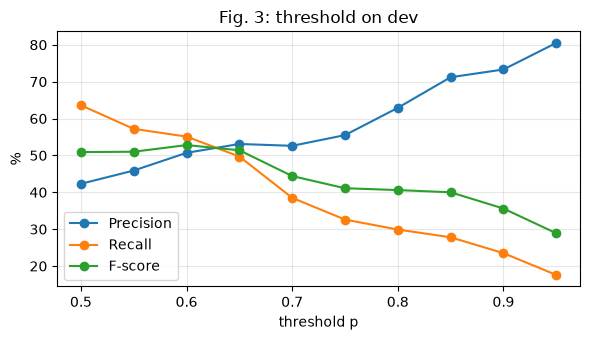

In [70]:
# Fig. 3 — threshold p from 0.5 to 0.95 on the new dev set (main model, no post-processing)
import matplotlib.pyplot as plt

thresholds = [round(0.5 + 0.05 * i, 2) for i in range(10)]
curve = [prf(predict_pairs(dev_instances, dev_probs, t), gold_dev) for t in thresholds]
for t, s in zip(thresholds, curve):
    print(f"p = {t:.2f}   P / R / F = {s}")

plt.figure(figsize=(6, 3.5))
for i, label in enumerate(["Precision", "Recall", "F-score"]):
    plt.plot(thresholds, [s[i] for s in curve], marker="o", label=label)
plt.xlabel("threshold p"); plt.ylabel("%"); plt.title("Fig. 3: threshold on dev")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

K = 1   P / R / F = (48.7, 51.9, 50.3)
K = 2   P / R / F = (45.8, 61.5, 52.5)
K = 3   P / R / F = (43.9, 63.1, 51.8)
K = 4   P / R / F = (42.3, 63.6, 50.9)
K = 5   P / R / F = (41.8, 63.6, 50.4)
K = 6   P / R / F = (41.3, 63.6, 50.1)


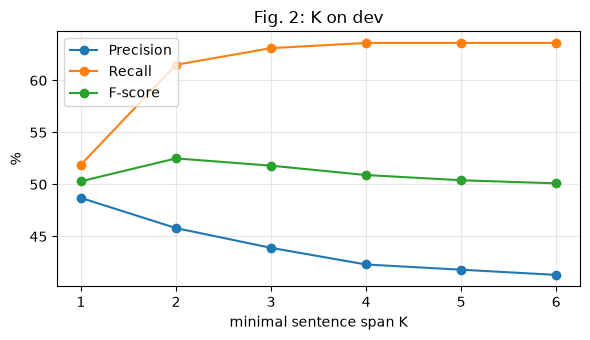

100368

In [71]:
# Fig. 2 — K from 1 to 6 on the new dev set.
# K only decides which dev pairs become candidates (training never uses K), so the main
# model is reused: predict every dev pair once, then keep pairs with span <= K.
dev_all = make_instances(new_dev_docs, k_limit=None)
X_dev_all, _ = encode(dev_all)
dev_all_probs = predict_probs(model, X_dev_all)

k_values = [1, 2, 3, 4, 5, 6]
k_curve = []
for k in k_values:
    pred_k = {(i["pmid"], i["chem"], i["dis"]) for i, p in zip(dev_all, dev_all_probs)
              if i["span"] <= k and p >= THRESHOLD}
    k_curve.append(prf(pred_k, gold_dev))
    print(f"K = {k}   P / R / F = {k_curve[-1]}")

plt.figure(figsize=(6, 3.5))
for i, label in enumerate(["Precision", "Recall", "F-score"]):
    plt.plot(k_values, [s[i] for s in k_curve], marker="o", label=label)
plt.xlabel("minimal sentence span K"); plt.ylabel("%"); plt.title("Fig. 2: K on dev")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()
del X_dev_all; gc.collect()

### Retraining experiments

Each experiment below trains a new model. To keep the RAM low:
- the data of an experiment is built **inside** `run_experiment` and freed when it ends;
- an experiment that is already in `results/results.json` is **skipped**.

If the kernel dies, restart it and use *Run All*: everything already done is loaded from
`results/` (prepared documents, embeddings, main model, scores), and the experiments carry on
where they stopped. Each experiment also prints the kernel's RAM, so you can watch it.

In [72]:
def save_preds(key, pred):
    (RESULTS_DIR / f"pred_{key}.json").write_text(json.dumps(sorted(pred)))


def load_preds(key):
    path = RESULTS_DIR / f"pred_{key}.json"
    return {tuple(x) for x in json.loads(path.read_text())} if path.is_file() else None


def run_experiment(key, make_data, **options):
    """Train a new model on the data that make_data() returns, test it at THRESHOLD
    (no post-processing), save its scores and predictions. Skipped if already done."""
    if key in RESULTS:
        print(f"{key}: already done {RESULTS[key]} (delete it from results.json to redo)")
        return RESULTS[key], load_preds(key)

    X_tr, y_tr, X_dv, dv_instances, dv_gold, X_te, te_instances = make_data()
    keras.backend.clear_session(); gc.collect()
    m = build_model(name=key, **options)
    print(f"\n=== {key} {options} | RAM {ram()} GB ===")
    train(m, X_tr, y_tr, X_dv, dv_instances, dv_gold,
          max_epochs=ABLATION_MAX_EPOCHS, patience=ABLATION_PATIENCE)
    pred = predict_pairs(te_instances, predict_probs(m, X_te), THRESHOLD)
    scores = prf(pred, gold)
    save_result(key, scores)
    save_preds(key, pred)

    del m, X_tr, y_tr, X_dv, X_te, dv_instances, te_instances
    keras.backend.clear_session(); gc.collect()
    print(f"{key}: test P / R / F = {scores} | RAM {ram()} GB")
    return scores, pred


def main_data():
    """The main split: the arrays already in memory (nothing new is built)."""
    return X_train, y_train, X_dev, dev_instances, gold_dev, X_test, test_instances


def no_marker_data():
    """Same split, but the text has NO ch_start / ds_start markers (Table 3)."""
    tr = make_instances(new_train_docs, k_limit=None, mark_entities=False)
    dv = make_instances(new_dev_docs, k_limit=K_WINDOW, mark_entities=False)
    te = make_instances(test_docs, k_limit=K_WINDOW, mark_entities=False)
    X_tr, y_tr = encode(tr)
    X_dv, _ = encode(dv)
    X_te, _ = encode(te)
    del tr
    return X_tr, y_tr, X_dv, dv, gold_dev, X_te, te


def train_500_data():
    """Only the original 500 training articles; early stopping on the original dev set (Table 9)."""
    tr = make_instances(train_docs, k_limit=None)
    dv = make_instances(dev_docs, k_limit=K_WINDOW)
    dv_gold = {(d["pmid"], c, s) for d in dev_docs for (c, s) in d["cids"]}
    X_tr, y_tr = encode(tr)
    X_dv, _ = encode(dv)
    del tr
    return X_tr, y_tr, X_dv, dv, dv_gold, X_test, test_instances

In [73]:
# Table 3 — input representation: word / word + POS / word + POS + entity markers
# Rows 1-2 use text WITHOUT ch_start/ds_start markers; row 3 is the main model.
if RUN_TABLE3_INPUTS:
    t3_word, _ = run_experiment("table3_word", no_marker_data, use_pos=False)
    t3_word_pos, pred_no_marks = run_experiment("table3_word_pos", no_marker_data, use_pos=True)

    print(f"\n{'Feature':<32}{'ours P / R / F':>22}{'paper P / R / F':>22}")
    for name, ours, paper_prf in [("word", t3_word, (24.2, 48.0, 32.2)),
                                  ("word + POS", t3_word_pos, (24.0, 52.0, 32.8)),
                                  ("word + POS + entities marked", RESULTS["main_no_pp"], (54.3, 65.9, 59.5))]:
        print(f"{name:<32}{str(ours):>22}{str(paper_prf):>22}")
    print()
    if pred_no_marks is not None:
        overlap_report(pred_no_marks, "Table 4, BEFORE entities are marked (word + POS model)")
        print("Paper, before marking: original 24.0/52.0/32.8 · non-overlapped 26.0/72.5/38.3")

table3_word: already done [23.7, 58.2, 33.7] (delete it from results.json to redo)
table3_word_pos: already done [24.2, 54.7, 33.6] (delete it from results.json to redo)

Feature                                 ours P / R / F       paper P / R / F
word                                [23.7, 58.2, 33.7]    (24.2, 48.0, 32.2)
word + POS                          [24.2, 54.7, 33.6]    (24.0, 52.0, 32.8)
word + POS + entities marked        (40.4, 62.0, 48.9)    (54.3, 65.9, 59.5)



In [74]:
# Table 6 — architecture: which document-level views help?
if RUN_TABLE6_ARCH:
    t6 = [
        ("table6_lstm_lstm",     dict(doc_views=("lstm",), use_title=False),        (48.0, 62.8, 54.4)),
        ("table6_lstm_cnn",      dict(doc_views=("cnn",), use_title=False),         (54.8, 59.2, 56.9)),
        ("table6_lstm_cnnlstm",  dict(doc_views=("lstm", "cnn"), use_title=False),  (56.5, 61.3, 58.8)),
    ]
    rows6 = []
    for key, options, paper_prf in t6:
        scores, _ = run_experiment(key, main_data, **options)
        rows6.append((key, scores, paper_prf))
    rows6.append(("lstm+cnnlstm+topic (main)", RESULTS["main_no_pp"], (54.3, 65.9, 59.5)))

    print(f"\n{'Architecture':<28}{'ours P / R / F':>22}{'paper P / R / F':>22}")
    for name, ours, paper_prf in rows6:
        print(f"{name.replace('table6_', ''):<28}{str(ours):>22}{str(paper_prf):>22}")

table6_lstm_lstm: already done [51.6, 52.6, 52.1] (delete it from results.json to redo)
table6_lstm_cnn: already done [27.2, 83.0, 41.0] (delete it from results.json to redo)

=== table6_lstm_cnnlstm {'doc_views': ('lstm', 'cnn'), 'use_title': False} | RAM 6.18 GB ===
Epoch 1/40
  epoch 1: dev P/R/F = 100.0 / 1.1 / 2.1
2414/2414 - 150s - 62ms/step - accuracy: 0.7873 - loss: 0.5392 - val_f1: 2.1000
Epoch 2/40
  epoch 2: dev P/R/F = 34.2 / 20.3 / 25.5
2414/2414 - 123s - 51ms/step - accuracy: 0.7928 - loss: 0.5248 - val_f1: 25.5000
Epoch 3/40
  epoch 3: dev P/R/F = 32.8 / 33.2 / 33.0
2414/2414 - 123s - 51ms/step - accuracy: 0.7827 - loss: 0.5419 - val_f1: 33.0000
Epoch 4/40
  epoch 4: dev P/R/F = 37.7 / 29.4 / 33.0
2414/2414 - 123s - 51ms/step - accuracy: 0.7904 - loss: 0.5394 - val_f1: 33.0000
Epoch 5/40
  epoch 5: dev P/R/F = 44.9 / 38.0 / 41.2
2414/2414 - 123s - 51ms/step - accuracy: 0.7986 - loss: 0.5361 - val_f1: 41.2000
Epoch 6/40
  epoch 6: dev P/R/F = 39.6 / 49.7 / 44.1
2414/2414 

In [75]:
# Table 9 — training data size: only the original 500 training articles
if RUN_TABLE9_DATA:
    t9, _ = run_experiment("table9_train_only", train_500_data)

    print(f"\n{'Training set':<28}{'ours P / R / F':>22}{'paper P / R / F':>22}")
    print(f"{'Only training (500)':<28}{str(t9):>22}{str((45.2, 68.1, 54.3)):>22}")
    print(f"{'Training + development (900)':<28}{str(RESULTS['main_no_pp']):>22}{str((54.3, 65.9, 59.5)):>22}")


=== table9_train_only {} | RAM 10.68 GB ===
Epoch 1/40
  epoch 1: dev P/R/F = 45.8 / 13.5 / 20.9
1358/1358 - 125s - 92ms/step - accuracy: 0.7793 - loss: 0.5654 - val_f1: 20.9000
Epoch 2/40
  epoch 2: dev P/R/F = 39.6 / 33.6 / 36.4
1358/1358 - 94s - 69ms/step - accuracy: 0.7971 - loss: 0.5103 - val_f1: 36.4000
Epoch 3/40
  epoch 3: dev P/R/F = 40.4 / 42.7 / 41.5
1358/1358 - 94s - 69ms/step - accuracy: 0.8041 - loss: 0.4918 - val_f1: 41.5000
Epoch 4/40
  epoch 4: dev P/R/F = 40.2 / 47.2 / 43.4
1358/1358 - 94s - 69ms/step - accuracy: 0.8071 - loss: 0.4856 - val_f1: 43.4000
Epoch 5/40
  epoch 5: dev P/R/F = 40.5 / 56.8 / 47.3
1358/1358 - 94s - 69ms/step - accuracy: 0.8139 - loss: 0.4747 - val_f1: 47.3000
Epoch 6/40
  epoch 6: dev P/R/F = 36.8 / 63.4 / 46.6
1358/1358 - 93s - 68ms/step - accuracy: 0.8181 - loss: 0.4783 - val_f1: 46.6000
Epoch 7/40
  epoch 7: dev P/R/F = 39.1 / 53.2 / 45.1
1358/1358 - 92s - 68ms/step - accuracy: 0.8255 - loss: 0.4621 - val_f1: 45.1000
Epoch 8/40
  epoch 8: d

In [76]:
# Optional — the full model with 3 seeds: results on a GPU change a little from run to run
if RUN_SEEDS:
    seed_scores = []
    for seed in [1, 2, 3]:
        random.seed(seed); np.random.seed(seed); tf.random.set_seed(seed)
        s, _ = run_experiment(f"seed_{seed}", main_data)
        seed_scores.append(s)
    arr = np.array(seed_scores)
    print("mean P / R / F:", arr.mean(axis=0).round(1), "| std:", arr.std(axis=0).round(1))
    save_result("seeds_mean", arr.mean(axis=0).round(1).tolist())

In [77]:
# Summary of every saved score (also in results/results.json)
for key, scores in RESULTS.items():
    print(f"{key:<24}{scores}")

main_no_pp              (40.4, 62.0, 48.9)
main_rule1              (40.6, 65.3, 50.1)
main_final              (44.0, 63.1, 51.8)
table5_rule2_only       (43.8, 59.9, 50.6)
table3_word             [23.7, 58.2, 33.7]
table3_word_pos         [24.2, 54.7, 33.6]
table6_lstm_lstm        [51.6, 52.6, 52.1]
table6_lstm_cnn         [27.2, 83.0, 41.0]
table6_lstm_cnnlstm     (50.5, 57.7, 53.9)
table9_train_only       (38.6, 50.4, 43.7)


## Part 10. Beyond the paper
One run is not enough on this corpus: the dev set has only 187 CIDs, so one CID is worth about
0.5 F-point and dev F jumps by several points from one epoch to the next. Every method below is
therefore trained with **3 seeds** and reported as **mean ± std**.

| Key in results.json | Method |
| --- | --- |
| `base_s1..3`        | paper model (baseline) |
| `pool_s1..3`        | + entity pooling |
| `select_s1..3`      | sentence selection (pair sentences ± 1) |
| `selpool_s1..3`     | sentence selection + entity pooling |


In [ ]:
# ---- Part 10 settings ----
N_SEEDS = 3                     # 1 = quick look, 3 = mean +/- std
SEEDS = [1, 2, 3][:N_SEEDS]
SELECT_NEIGHBOURS = 1           # 10.3: keep pair sentences +/- this many neighbours
RUN_BASELINE  = True
RUN_POOLING   = True
RUN_SELECTION = True
RUN_SEL_POOL  = True

# Save the split, so the transformer notebook (Part 11) uses exactly the same articles.
split = {"train": [d["pmid"] for d in new_train_docs],
         "dev":   [d["pmid"] for d in new_dev_docs],
         "test":  [d["pmid"] for d in test_docs]}
(RESULTS_DIR / "split.json").write_text(json.dumps(split))


def run_seeded(name, make_data, builder=build_model, **options):
    """Train one model per seed. Keys: name_s1, name_s2, ... Finished seeds are skipped.
    Saves scores (results.json), predictions (pred_<key>.json) and test probabilities
    (probs_<key>.npy, same order as the test instances)."""
    for seed in SEEDS:
        key = f"{name}_s{seed}"
        if key in RESULTS:
            print(f"{key}: already done {RESULTS[key]}")
            continue

        X_tr, y_tr, X_dv, dv_inst, dv_gold, X_te, te_inst = make_data()
        keras.backend.clear_session(); gc.collect()
        keras.utils.set_random_seed(seed)                 # python, numpy and TF seeds
        m = builder(name=key, **options)
        print(f"\n=== {key} {options} | RAM {ram()} GB ===")
        train(m, X_tr, y_tr, X_dv, dv_inst, dv_gold,
              max_epochs=ABLATION_MAX_EPOCHS, patience=ABLATION_PATIENCE)

        probs = predict_probs(m, X_te)
        pred = predict_pairs(te_inst, probs, THRESHOLD)
        save_result(key, prf(pred, gold))
        save_preds(key, pred)
        np.save(RESULTS_DIR / f"probs_{key}.npy", probs)
        print(f"{key}: test P / R / F = {RESULTS[key]} | RAM {ram()} GB")

        del m, X_tr, y_tr, X_dv, X_te, dv_inst, te_inst, probs
        keras.backend.clear_session(); gc.collect()


def seed_preds(name):
    """Predictions of every finished seed of a method."""
    return [p for p in (load_preds(f"{name}_s{s}") for s in SEEDS) if p is not None]


def mean_std(rows):
    a = np.array(rows, dtype=float)
    return [f"{m:.1f} ± {s:.1f}" for m, s in zip(a.mean(axis=0), a.std(axis=0))]


In [ ]:
# The paper's model, 3 seeds. This is the line every other method is compared with.
if RUN_BASELINE:
    run_seeded("base", main_data)
    print("\nbaseline P / R / F (mean ± std):",
          mean_std([prf(p, gold) for p in seed_preds("base")]))


### 10.2 Entity pooling
The paper gives the classifier one vector per sentence (the LSTM's *last* state) and never looks
at the words of the two entities directly. Here the word BiLSTM keeps the state of **every**
word, and two extra vectors are added before the softmax:

- **chemical vector** = mean of the word states at every mention of the candidate chemical
- **disease vector**  = mean of the word states at every mention of the candidate disease

This adds **no new weights** to the LSTMs (unlike the attention the paper tried, which lost
2–3 F on this small corpus). It is the "entity pooling" used by modern models such as ATLOP.


In [ ]:
def mark_positions(words, chem_row, dis_row):
    """1.0 at the word right after ch_start (the chemical ID) and after ds_start."""
    for j in range(1, min(len(words), MAX_WORDS)):
        if words[j - 1] == "ch_start":
            chem_row[j] = 1.0
        elif words[j - 1] == "ds_start":
            dis_row[j] = 1.0


def entity_positions(instances):
    """Same layout as encode(): abstract sentences from row 0, words from column 0."""
    n = len(instances)
    pos = {"chem_pos":       np.zeros((n, MAX_SENTS, MAX_WORDS), dtype="float32"),
           "dis_pos":        np.zeros((n, MAX_SENTS, MAX_WORDS), dtype="float32"),
           "chem_pos_title": np.zeros((n, MAX_WORDS), dtype="float32"),
           "dis_pos_title":  np.zeros((n, MAX_WORDS), dtype="float32")}
    for k, inst in enumerate(instances):
        sents = inst["abstract"][:MAX_SENTS] or [inst["title"]]      # as in encode()
        for s, (words, _) in enumerate(sents):
            mark_positions(words, pos["chem_pos"][k, s], pos["dis_pos"][k, s])
        mark_positions(inst["title"][0], pos["chem_pos_title"][k], pos["dis_pos_title"][k])
    return pos


def with_positions(X, instances):
    X = dict(X)                     # a new dict; the big arrays are shared, not copied
    X.update(entity_positions(instances))
    return X


# How often is an entity cut off (beyond 30 sentences or 120 words)? Its vector is then 0.
P = entity_positions(test_instances)
chem_found = (P["chem_pos"].sum(axis=(1, 2)) + P["chem_pos_title"].sum(axis=1)) > 0
dis_found = (P["dis_pos"].sum(axis=(1, 2)) + P["dis_pos_title"].sum(axis=1)) > 0
print(f"test pairs: chemical found {chem_found.mean():.1%}, disease found {dis_found.mean():.1%}")
del P


In [ ]:
class SentenceFromStates(layers.Layer):
    """S'_i from the states of every word: forward state at the LAST real word || backward
    state at the FIRST word. It is the same vector as BiLSTM(return_sequences=False) gives,
    but the word states stay available for the entity pooling."""
    def __init__(self, units, **kwargs):
        super().__init__(**kwargs)
        self.units = units
        self.supports_masking = True

    def call(self, states, word_ids):
        n_words = keras.ops.sum(keras.ops.cast(keras.ops.not_equal(word_ids, 0), "int32"), axis=-1)
        last = keras.ops.one_hot(keras.ops.maximum(n_words - 1, 0), keras.ops.shape(word_ids)[-1])
        forward = keras.ops.sum(states[..., :self.units] * keras.ops.expand_dims(last, -1), axis=-2)
        backward = states[..., 0, self.units:]
        return keras.ops.concatenate([forward, backward], axis=-1)

    def compute_mask(self, *args, **kwargs):
        return None


class EntityPool(layers.Layer):
    """Mean of the word states at the entity's positions, in the abstract and the title.
    Gives 0 if the entity was cut off."""
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.supports_masking = True

    def call(self, doc_states, doc_pos, title_states, title_pos):
        total = (keras.ops.sum(doc_states * keras.ops.expand_dims(doc_pos, -1), axis=(1, 2))
                 + keras.ops.sum(title_states * keras.ops.expand_dims(title_pos, -1), axis=1))
        count = keras.ops.sum(doc_pos, axis=(1, 2)) + keras.ops.sum(title_pos, axis=1)
        return total / keras.ops.expand_dims(keras.ops.maximum(count, 1.0), -1)

    def compute_mask(self, *args, **kwargs):
        return None


In [ ]:
def build_model_pool(name="cid_entity_pool"):
    """The paper's model + a chemical vector and a disease vector before the softmax."""
    inputs = make_inputs()                                          # M1
    for key, shape in [("chem_pos", (MAX_SENTS, MAX_WORDS)), ("dis_pos", (MAX_SENTS, MAX_WORDS)),
                       ("chem_pos_title", (MAX_WORDS,)), ("dis_pos_title", (MAX_WORDS,))]:
        inputs[key] = keras.Input(shape=shape, dtype="float32", name=key)
    doc_x, title_x = embed(inputs)                                  # M2

    # M3, changed: the word BiLSTM returns the state of EVERY word
    word_lstm = layers.Bidirectional(layers.LSTM(110, return_sequences=True), name="bilstm1_words")
    doc_states = layers.TimeDistributed(word_lstm, name="each_sentence")(doc_x)    # (b, 30, 120, 220)
    sentence_vectors = SentenceFromStates(110, name="sentence_vectors")(doc_states, inputs["doc_words"])
    sent_mask = SentenceMask(name="sentence_mask")(inputs["doc_words"])
    sentence_vectors = ZeroEmptySentences(name="zero_empty")(sentence_vectors, sent_mask)
    sentence_vectors = layers.Dropout(DROPOUT)(sentence_vectors)

    D_l = doc_bilstm(sentence_vectors, sent_mask)                   # M4
    D_c = doc_cnn(sentence_vectors)                                 # M5

    # M6, changed: the title BiLSTM also returns every word's state
    title_states = layers.Bidirectional(layers.LSTM(110, return_sequences=True),
                                        name="bilstm3_title")(title_x)              # (b, 120, 220)
    D_t = SentenceFromStates(110, name="title_vector")(title_states, inputs["title_words"])
    D_t = layers.Dropout(DROPOUT)(D_t)

    # NEW: one vector for each entity of the pair
    chem_vec = EntityPool(name="chemical_vector")(doc_states, inputs["chem_pos"],
                                                  title_states, inputs["chem_pos_title"])
    dis_vec = EntityPool(name="disease_vector")(doc_states, inputs["dis_pos"],
                                                title_states, inputs["dis_pos_title"])
    chem_vec = layers.Dropout(DROPOUT)(chem_vec)
    dis_vec = layers.Dropout(DROPOUT)(dis_vec)

    model = keras.Model(inputs=inputs, outputs=classify([D_l, D_c, D_t, chem_vec, dis_vec]),
                        name=name)                                  # M7
    model.compile(optimizer=keras.optimizers.RMSprop(learning_rate=LEARNING_RATE, rho=0.9),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model


def pool_data():
    """The main arrays + the entity positions."""
    return (with_positions(X_train, train_instances), y_train,
            with_positions(X_dev, dev_instances), dev_instances, gold_dev,
            with_positions(X_test, test_instances), test_instances)


keras.backend.clear_session()
build_model_pool().summary()


In [ ]:
if RUN_POOLING:
    run_seeded("pool", pool_data, builder=build_model_pool)
    print("\nentity pooling P / R / F (mean ± std):",
          mean_std([prf(p, gold) for p in seed_preds("pool")]))


### 10.3 Sentence selection
The authors explain their low precision by "noise from the whole document". This tests that
claim: each instance keeps only the abstract sentences that mention the chemical or the
disease, plus `SELECT_NEIGHBOURS` sentences on each side (the title is always kept). The model
is unchanged. If the entities appear only in the title, the whole abstract is kept.


In [ ]:
def select_sentences(inst, n=SELECT_NEIGHBOURS):
    """Keep the abstract sentences that contain a marked entity, +/- n neighbours."""
    keep = set()
    for i, (words, _) in enumerate(inst["abstract"]):
        if "ch_start" in words or "ds_start" in words:
            keep.update(range(i - n, i + n + 1))
    if not keep:
        return inst
    new = dict(inst)
    new["abstract"] = [s for i, s in enumerate(inst["abstract"]) if i in keep]
    return new


def select_data(n=SELECT_NEIGHBOURS, positions=False):
    tr = [select_sentences(i, n) for i in train_instances]
    dv = [select_sentences(i, n) for i in dev_instances]
    te = [select_sentences(i, n) for i in test_instances]
    X_tr, y_tr = encode(tr)
    X_dv, _ = encode(dv)
    X_te, _ = encode(te)
    if positions:                                   # for selection + entity pooling
        X_tr, X_dv, X_te = with_positions(X_tr, tr), with_positions(X_dv, dv), with_positions(X_te, te)
    return X_tr, y_tr, X_dv, dv, gold_dev, X_te, te


# How much text is removed?
before = [len(i["abstract"]) for i in test_instances]
after = [len(select_sentences(i)["abstract"]) for i in test_instances]
print(f"test: {np.mean(before):.1f} -> {np.mean(after):.1f} abstract sentences per pair on average")
print(f"pairs with more than {MAX_SENTS} sentences: before {sum(b > MAX_SENTS for b in before)}, "
      f"after {sum(a > MAX_SENTS for a in after)}  (selection also rescues entities cut off at sentence {MAX_SENTS})")


In [ ]:
if RUN_SELECTION:
    run_seeded("select", select_data)
    print("\nselection P / R / F (mean ± std):",
          mean_std([prf(p, gold) for p in seed_preds("select")]))

if RUN_SEL_POOL:
    run_seeded("selpool", lambda: select_data(positions=True), builder=build_model_pool)
    print("selection + pooling P / R / F (mean ± std):",
          mean_std([prf(p, gold) for p in seed_preds("selpool")]))


### 10.4 Comparison
For each method: mean ± std over the seeds, without and with the two post-processing rules,
and the F-score on same-sentence (intra) and cross-sentence (inter) CIDs.

**Is a difference real?** A paired bootstrap over the 500 test articles: draw 500 articles with
replacement 1,000 times, compute F(method) − F(baseline) each time (all seeds pooled). If the
95 % interval does not contain 0, the difference is unlikely to be luck.


In [ ]:
methods = [("base", "Paper model (baseline)"), ("pool", "+ entity pooling"),
           ("select", "Sentence selection"), ("selpool", "Selection + pooling")]
test_pmids = [d["pmid"] for d in test_docs]


def doc_counts(preds_list):
    """Per test article: TP, predicted and gold counts, summed over the seeds."""
    tp, n_pred, n_gold = Counter(), Counter(), Counter()
    for pred in preds_list:
        for x in pred:
            n_pred[x[0]] += 1
            tp[x[0]] += x in gold
        for x in gold:
            n_gold[x[0]] += 1
    return [np.array([c[p] for p in test_pmids], dtype=float) for c in (tp, n_pred, n_gold)]


def bootstrap_diff(preds_a, preds_b, n_boot=1000, seed=0):
    """95% interval of F(a) - F(b), resampling test articles."""
    a, b = doc_counts(preds_a), doc_counts(preds_b)
    rng = np.random.default_rng(seed)
    def f(tp, n_pred, n_gold):
        p, r = tp.sum() / max(n_pred.sum(), 1), tp.sum() / max(n_gold.sum(), 1)
        return 200 * p * r / (p + r) if p + r else 0.0
    diffs = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(test_pmids), len(test_pmids))
        diffs.append(f(*(x[idx] for x in a)) - f(*(x[idx] for x in b)))
    return np.mean(diffs), np.percentile(diffs, 2.5), np.percentile(diffs, 97.5)


def intra_inter_f(pred):
    rows = []
    for wanted in (True, False):
        g = {x for x in gold if is_intra(*x) == wanted}
        p = {x for x in pred if is_intra(*x) == wanted}
        rows.append(prf(p, g)[2])
    return rows


base_preds = seed_preds("base")
print(f"{'Method':<24}{'seeds':>6}   {'P / R / F (no rules)':<38}{'F + rules':<14}"
      f"{'F intra':<14}{'F inter':<14}{'ΔF vs base [95% CI]'}")
for name, label in methods:
    preds = seed_preds(name)
    if not preds:
        print(f"{label:<24}  (not run yet)")
        continue
    no_rules = mean_std([prf(p, gold) for p in preds])
    rules = mean_std([prf(rule_2(rule_1(p, test_docs), test_docs), gold) for p in preds])[2]
    ii = mean_std([intra_inter_f(p) for p in preds])
    delta = "—"
    if name != "base" and base_preds:
        d, lo, hi = bootstrap_diff(preds, base_preds)
        delta = f"{d:+.1f} [{lo:+.1f}, {hi:+.1f}]"
    print(f"{label:<24}{len(preds):>6}   {' / '.join(no_rules):<38}{rules:<14}"
          f"{ii[0]:<14}{ii[1]:<14}{delta}")

print("\nPaper (single run): 54.3 / 65.9 / 59.5 without rules, 61.5 with rules; intra 65.3, inter 44.0")


### 10.5 Error analysis
The paper reports only scores. Here every false positive (FP: predicted CID, not in gold) and
false negative (FN: gold CID, missed) of the baseline (seed 1) gets automatic tags:

| Tag | Meaning |
| --- | --- |
| `treatment cue` | a sentence with both entities contains a treatment word (treat, prevent, protect, reverse, …) |
| `general disease` | the article has a more specific disease than this one (rule 2's job) |
| `cross-sentence` | chemical and disease never share a sentence |
| `beyond K` | they are more than K = 4 sentences apart (FN the model could never find) |
| `cut off` | a mention lies beyond sentence 30 or word 120, so the model never saw it |
| `single mention` | the chemical or the disease is mentioned only once |
| `seen as CID` / `seen as non-CID` | the same pair is a CID / a non-CID somewhere in the training articles |

Then a CSV with 100 FPs and 100 FNs and their sentences is written for **manual labels**,
which is what turns the numbers into findings.


In [ ]:
TREATMENT_CUES = ("treat", "therap", "prevent", "protect", "revers", "attenuat", "inhibit",
                  "antagon", "improv", "benefi", "efficac", "alleviat", "amelior", "relie", "against")
ANALYSE = "base_s1"                     # which run to analyse

pred_a = load_preds(ANALYSE)
probs_a = np.load(RESULTS_DIR / f"probs_{ANALYSE}.npy")
prob_of = {(i["pmid"], i["chem"], i["dis"]): p for i, p in zip(test_instances, probs_a)}
span_of = {(d["pmid"], c, s): sp for d in test_docs for c, s, _, sp in candidate_pairs(d)}
train_cid = {(c, d) for doc in new_train_docs for c, d in doc["cids"]}
train_cand = {(c, d) for doc in new_train_docs for c, d, _, _ in candidate_pairs(doc)}


def mention_count(doc, eid):
    return sum(eid in e["ids"] for e in doc["entities"])


def pair_sentences(doc, c, d):
    """Sentences (title = 0) that contain the marked chemical or disease, as plain text."""
    out = []
    for i, (words, _) in enumerate(render(doc, c, d)):
        has_c, has_d = "ch_start" in words, "ds_start" in words
        if has_c or has_d:
            out.append((i, has_c and has_d, " ".join(words)))
    return out


def cut_off(doc, c, d):
    """True if every mention of c (or of d) is beyond sentence 30 or word 120."""
    sents = render(doc, c, d)
    for marker in ("ch_start", "ds_start"):
        seen = False
        for i, (words, _) in enumerate(sents):
            if marker in words:
                j = words.index(marker)
                if (i == 0 or i - 1 < MAX_SENTS) and j + 1 < MAX_WORDS:
                    seen = True
        if not seen:
            return True
    return False


def tags_for(pmid, c, d):
    doc = doc_by_pmid[pmid]
    tags = []
    sents = pair_sentences(doc, c, d)
    both = " ".join(text for _, together, text in sents if together).lower()
    if any(cue in both for cue in TREATMENT_CUES):
        tags.append("treatment cue")
    diseases = {i for e in doc["entities"] if e["type"] == "Disease" for i in e["ids"]}
    if any(more_general(d, other) for other in diseases if other != d):
        tags.append("general disease")
    if not is_intra(pmid, c, d):
        tags.append("cross-sentence")
    if span_of.get((pmid, c, d), 0) > K_WINDOW:
        tags.append("beyond K")
    if cut_off(doc, c, d):
        tags.append("cut off")
    if min(mention_count(doc, c), mention_count(doc, d)) == 1:
        tags.append("single mention")
    if (c, d) in train_cid:
        tags.append("seen as CID")
    elif (c, d) in train_cand:
        tags.append("seen as non-CID")
    return tags


false_pos = sorted(pred_a - gold)
false_neg = sorted(gold - pred_a)
fp_tags = {x: tags_for(*x) for x in false_pos}
fn_tags = {x: tags_for(*x) for x in false_neg}

all_tags = ["treatment cue", "general disease", "cross-sentence", "beyond K", "cut off",
            "single mention", "seen as CID", "seen as non-CID"]
print(f"{ANALYSE}: {len(false_pos)} false positives, {len(false_neg)} false negatives\n")
print(f"{'Tag':<18}{'FP':>6}{'% FP':>8}{'FN':>6}{'% FN':>8}")
for t in all_tags:
    n_fp = sum(t in v for v in fp_tags.values())
    n_fn = sum(t in v for v in fn_tags.values())
    print(f"{t:<18}{n_fp:>6}{100 * n_fp / max(len(false_pos), 1):>7.1f}%"
          f"{n_fn:>6}{100 * n_fn / max(len(false_neg), 1):>7.1f}%")
print("(an error can have several tags, or none)")


In [ ]:
SHOW_TAG = "treatment cue"      # change to any tag of the table
SHOW_KIND = "FP"                # "FP" or "FN"

pool = fp_tags if SHOW_KIND == "FP" else fn_tags
examples = [x for x, t in pool.items() if SHOW_TAG in t][:3]
for pmid, c, d in examples:
    print(f"--- {SHOW_KIND} {pmid} {c} {d}  P(CID) = {prob_of.get((pmid, c, d), float('nan')):.2f}")
    for i, together, text in pair_sentences(doc_by_pmid[pmid], c, d)[:4]:
        print(f"  [{'title' if i == 0 else 'sent ' + str(i)}]{' (both)' if together else ''} {text}")


In [ ]:
import csv

LABELS = ["correct (annotation gap)", "treatment / protective", "too general disease",
          "side mention (not the article's focus)", "hypothesis / negation", "other"]


def entity_name(doc, eid):
    text = doc["title"] + " " + doc["abstract"]
    for e in doc["entities"]:
        if eid in e["ids"]:
            return text[e["start"]:e["end"]]
    return eid


rng = random.Random(0)
sample = ([("FP", x) for x in rng.sample(false_pos, min(100, len(false_pos)))]
          + [("FN", x) for x in rng.sample(false_neg, min(100, len(false_neg)))])

csv_path = RESULTS_DIR / f"error_analysis_{ANALYSE}.csv"
with open(csv_path, "w", newline="", encoding="utf-8") as f:
    w = csv.writer(f)
    w.writerow(["kind", "pmid", "chem_id", "dis_id", "chemical", "disease", "p_cid",
                "auto_tags", "evidence", "manual_label", "notes"])
    for kind, (pmid, c, d) in sample:
        doc = doc_by_pmid[pmid]
        evidence = " || ".join(text for _, _, text in pair_sentences(doc, c, d)[:3])
        w.writerow([kind, pmid, c, d, entity_name(doc, c), entity_name(doc, d),
                    round(float(prob_of.get((pmid, c, d), float("nan"))), 3),
                    "; ".join(tags_for(pmid, c, d)), evidence, "", ""])
print("Written", csv_path)
print("Fill the 'manual_label' column with one of:", LABELS)


In [ ]:
with open(csv_path, encoding="utf-8") as f:
    rows = list(csv.DictReader(f))
labelled = [r for r in rows if r["manual_label"].strip()]
print(f"{len(labelled)} of {len(rows)} rows labelled\n")
for kind in ("FP", "FN"):
    counts = Counter(r["manual_label"].strip() for r in labelled if r["kind"] == kind)
    total = sum(counts.values())
    print(kind)
    for label, n in counts.most_common():
        print(f"  {label:<40}{n:>4}  ({100 * n / max(total, 1):.0f}%)")


## Notes vs the paper

| Point | Paper | This notebook |
| --- | --- | --- |
| Sentence / POS | Stanford CoreNLP | CoreNLP if `CORENLP_HOME`+Java; else Stanza |
| Word vectors | word2vec on ~22 GB PubTator offsets + CDR | `scripts/build_pubtator_embeddings.py` on PubTator3 **BioCXML** + CDR (offsets file retired by NCBI) |
| POS vectors | word2vec on ~1/5 tagged PubTator text | same script: Stanza POS on a 1/5 sample (capped), else CDR fallback |
| Train/dev split | 10 equal article subsets of train∪dev; K only on new dev and test | same (§3.1); seed 100, subset 3 matches Table 2 CID counts |
| Relations with span > K | false negatives (3 dev, 24 test) | counted in gold; test matches 24, dev matches 3 |
| Epochs | not stated | early stopping on dev F1 (threshold 0.5), patience 5 |
| Padding | not stated | right padding + masks (LSTMs skip padding) |
| Class weights | none | none by default (`USE_CLASS_WEIGHT`) |
| Batch size | 8 | 4 (6 GB GPU) |
| Hidden sizes | 220 / 440 / 220 outputs | BiLSTM(110)/ (220)/ (110) bidirectional |

Build embeddings (once):

```bash
source dl/bin/activate
python scripts/build_pubtator_embeddings.py --download
```

Exploration of the raw CDR files remains in `Proj2.ipynb`.